# Dolphin Swarm Algorithm (DSA) for quadrotor controller tuning

**Author: Mohammad ALbaraj**

[Notebook index](README.md) · [Main project](../README.md)

Run cells from top to bottom. Saved results and fresh examples are labeled separately. Scientific source modules remain the authoritative implementation.


In [1]:
from pathlib import Path
import sys, json, csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code

# Works when launched from the repository root or any notebook subdirectory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'CITATION.cff').exists() and (p / 'all work').is_dir())
if str(ROOT / 'notebooks') not in sys.path:
    sys.path.insert(0, str(ROOT / 'notebooks'))
from notebook_support import (METHODS, ORIGINAL, NOMINAL, ROBUST, study, load_json,
    load_csv, show_table, show_source, source_index, load_runs, fitness_summary,
    convergence_plot, validation_rows, validation_summary, figures, file_links,
    show_figures, gallery, isolated_python, demo_source)
plt.rcParams.update({'figure.dpi': 100, 'font.size': 10})
print('Project loaded. Default cells do not launch full optimization campaigns.')


Project loaded. Default cells do not launch full optimization campaigns.


## Algorithm walkthrough

The bounded Wu–Yao–Yang-style implementation separates local search, communication, and predation.

1. Initialize 64 dolphins and their stored knowledge in normalized log-gain space.
2. Probe two random unit directions at two distances (sound speed 0.08 times search ticks 1 and 2). Clip probes to the domain.
3. Store better local discoveries. Communication delays depend on pairwise distance divided by sound speed × acceleration (10), rounded upward with a minimum of one tick.
4. On message arrival, adopt better sender knowledge.
5. Near known prey, contract the position toward it by factor `1-2/reduction`; otherwise sample a direction around the known point with the fitness-ratio-based predation radius. Reduction is 3.
6. Evaluate predation positions and update the archive; repeat 50 updates.

The maximum transmission timer is 1,000,000. Fitness ratios require nonnegative fitness. Multiple search probes make iteration-count comparisons unequal in cost; use the strict-budget results for paired comparisons.

Read [dsa.py](../all%20work/pid%20using%20dolphin%20swarm/dsa.py) for the implemented update rules, [config.json](../all%20work/pid%20using%20dolphin%20swarm/config.json) for settings, and [study.py](../all%20work/pid%20using%20dolphin%20swarm/study.py) for objective evaluation.


In [2]:
METHOD='DSA'
FOLDER=study(METHOD)
cfg=load_json(FOLDER/'config.json')
show_table([{'setting':k,'value':v} for k,v in cfg.items() if k!='parameters'],limit=60)


setting,value
study_name,Equation-based Dolphin Swarm Algorithm tuning of AttitudeControl_Sim
integration_dt_s,0.001
controller_dt_s,0.001
mixer_dt_s,0.004
pre_step_s,0.2
response_horizon_s,3.0
settling_band_fraction,0.02
minimum_final_hold_s,0.25
max_overshoot_fraction,0.1
max_final_error_fraction,0.02


## Exact implementation
This displays the authoritative Python source rather than a separately reimplemented optimizer. The six extensions share one module containing their distinct update rules.


In [3]:
show_source(FOLDER/METHODS[METHOD][2])


"""Bounded Wu-Yao-Yang Dolphin Swarm Algorithm; see STUDY_METHOD.md."""
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import json,time
import numpy as np
from model import baseline
from study import decode,encode,evaluate,write_csv

def predation_radius(distance, local_distance, best_fitness, local_fitness, reduction):
    # Algebraic simplification of both outer-radius cases, equations 20 and 23.
    ratio=best_fitness/max(local_fitness,1e-300)
    return max(0.,distance-(distance+(distance-local_distance)*ratio)/reduction)

def communicate(x,k,kf,timers,speed,acceleration,maximum):
    distance=np.linalg.norm(x[:,None,:]-x[None,:,:],axis=2)
    delay=np.maximum(1,np.ceil(distance/(speed*acceleration))).astype(np.int64)
    better=kf[:,None]>kf[None,:]
    timers=np.where(better & (timers>delay),delay,timers)-1
    arrived=timers<=0
    nextk=k.copy(); nextf=kf.copy(); adopted=0
    for i in range(len(x)):
        senders=np.flatnonzero(arrived[i] & better[i])
        if len(senders):
            j=senders[np.argmin(kf[senders])]
            nextk[i]=k[j]; nextf[i]=kf[j]; adopted+=1
    timers[arrived]=maximum
    return nextk,nextf,timers,adopted

def dolphin_swarm(cfg,scenarios,seed,outdir,initial=None,label='main',objective=None):
    outdir=Path(outdir); outdir.mkdir(parents=True,exist_ok=True)
    n=int(cfg['swarm_size']); d=len(cfg['parameters']); m=int(cfg['sound_directions']); ticks=int(cfg['search_time_steps'])
    speed=float(cfg['sound_speed']); reduction=float(cfg['radius_reduction'])
    if min(n,m,ticks,cfg['iterations'])<1 or n<2 or speed<=0 or reduction<=2 or cfg['communication_acceleration']<=0:
        raise ValueError('Invalid Dolphin Swarm settings')
    rng=np.random.default_rng(seed); x=rng.random((n,d))
    for j in range(d): x[:,j]=(rng.permutation(n)+rng.random(n))/n
    x[0]=encode(baseline(cfg['controller_dt_s']),cfg)
    if initial is not None: x[1]=encode(np.asarray(initial),cfg)
    names=[p['name'] for p in cfg['parameters']]
    archive=x[0].copy(); best=float('inf'); cache={}; history=[]; rows=[]; evaluations=[]
    start=time.perf_counter(); proposals=0; iteration=0; phase='initial'
    def raw_score(unit):
        gains=decode(unit,cfg)
        f=objective(gains) if objective is not None else evaluate(gains,scenarios,cfg)
        if np.isfinite(f) and f<0: raise ValueError('DSA fitness ratios require nonnegative fitness')
        return float(f) if np.isfinite(f) else 1e12
    first_value=raw_score(x[0])
    with ThreadPoolExecutor(max_workers=cfg['workers']) as pool:
        def evaluate_points(points):
            nonlocal archive,best,proposals,first_value
            proposals+=len(points); keys=[tuple(np.round(p,13)) for p in points]; new={}
            for key,p in zip(keys,points):
                if key not in cache and key not in new: new[key]=p.copy()
            items=list(new.items()); todo=[]; scores={}; first_key=tuple(np.round(x[0],13))
            for key,p in items:
                if first_value is not None and key==first_key: scores[key]=first_value; first_value=None
                else: todo.append((key,p))
            for (key,p),f in zip(todo,pool.map(raw_score,[p for _,p in todo])): scores[key]=f
            for key,p in items:
                f=scores[key]; cache[key]=f
                if f<best: best=f; archive=p.copy()
                evaluations.append({'evaluation':len(cache),'iteration':iteration,'phase':phase,'fitness':f,'best_so_far':best,**dict(zip(names,decode(p,cfg)))})
            return np.array([cache[key] for key in keys])
        values=evaluate_points(x); k=x.copy(); kf=values.copy()
        timers=np.full((n,n),cfg['maximum_transmission_time'],dtype=np.int64)
        adopted=0; near_count=0
        for iteration in range(cfg['iterations']+1):
            if iteration:
                phase='search'
                directions=rng.normal(size=(n,m,d)); directions/=np.linalg.norm(directions,axis=2,keepdims=True)
            

## Original three-seed study
These iteration-based results are separate from the strict-budget benchmark below. Unique evaluation counts differ across methods.


In [4]:
original_runs=[load_json(FOLDER/f'results/run_main_{seed}.json') for seed in [11,29,47]]
show_table(original_runs,['seed','fitness','unique_evaluations','seconds'])
show_table([{'gain':k,'value':v} for k,v in load_json(FOLDER/'results/best_gains.json')['gains'].items()])


seed,fitness,unique_evaluations,seconds
11,0.05369302125994019,15105,60.466065799992066
29,0.0537100535163189,15580,58.073571200016886
47,0.0527023006368179,15055,62.67756759998156


gain,value
roll_outer_K,11.2401120563629
roll_inner_Kp_equivalent,0.06805499219938767
roll_inner_Ki_equivalent,0.006337209499187304
pitch_outer_K,16.264564303153083
pitch_inner_Kp_equivalent,0.15788271665036321
pitch_inner_Ki_equivalent,0.027818950242397722
yaw_Kp,0.38994983394134425
yaw_Ki,0.05555746964188564


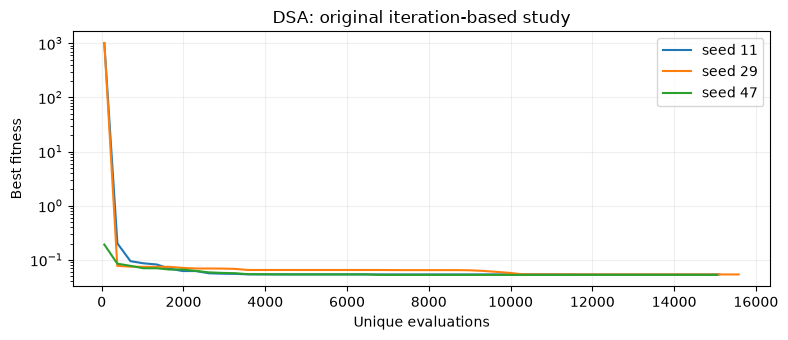

In [5]:
fig,ax=plt.subplots(figsize=(8,3.5))
for record in original_runs:
    history=record['history']
    ax.plot([h['unique_evaluations'] for h in history],[h['best'] for h in history],label=f"seed {record['seed']}")
ax.set(xlabel='Unique evaluations',ylabel='Best fitness',yscale='log',title=f'{METHOD}: original iteration-based study')
ax.legend(); ax.grid(alpha=.2); fig.tight_layout(); plt.show(); plt.close(fig)


## Paired 30-seed results
These summaries are recomputed from saved run records. Nominal and robust fitness use different training sets. Means retain infeasible penalties; medians alone can hide a failed run.


method,regime,runs,best,median,mean,sample_sd,feasible
DSA,nominal,30,0.05226800719584598,0.05702833085335258,0.05870858887815674,0.004588144239095514,30
DSA,robust,30,0.06650325721236684,0.07020261902729469,0.07004076356282862,0.002327064182525687,30


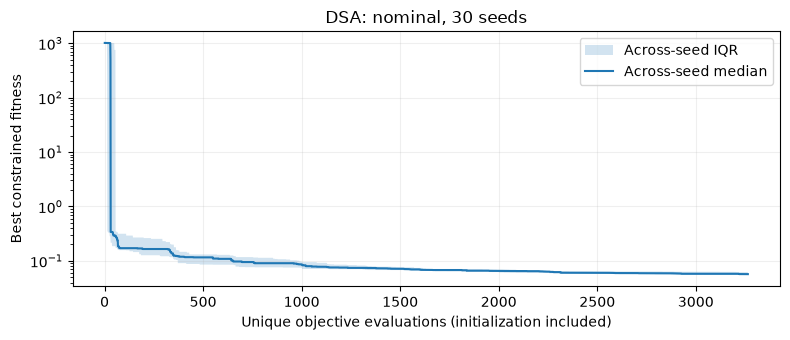

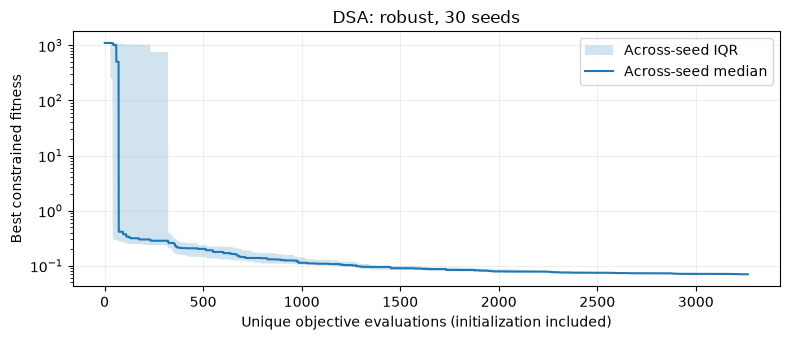

In [6]:
show_table(fitness_summary([METHOD]))
convergence_plot(METHOD,"nominal")
convergence_plot(METHOD,"robust")


## Held-out validation
Each later validation suite contains 300 random single-axis, 54 one-factor boundary, and 90 combined-axis cases. The table gives the range across seeds, not an independent probability of hardware success.


In [7]:
show_table(validation_summary(METHOD))


method,training,suite,cases_per_controller,minimum_passes,median_passes,maximum_passes
DSA,nominal,Random single-axis,300,269,296.5,300
DSA,nominal,One-factor boundaries,54,46,50.0,52
DSA,nominal,Combined-axis stress,90,0,0.0,0
DSA,robust,Random single-axis,300,300,300.0,300
DSA,robust,One-factor boundaries,54,52,53.0,54
DSA,robust,Combined-axis stress,90,0,0.0,0


## Saved figures
The first three images are previews; the full index below links every saved PNG for this method. The complete gallery notebook covers all methods.


**all work/pid using dolphin swarm/results/plots/01_step_responses.png**

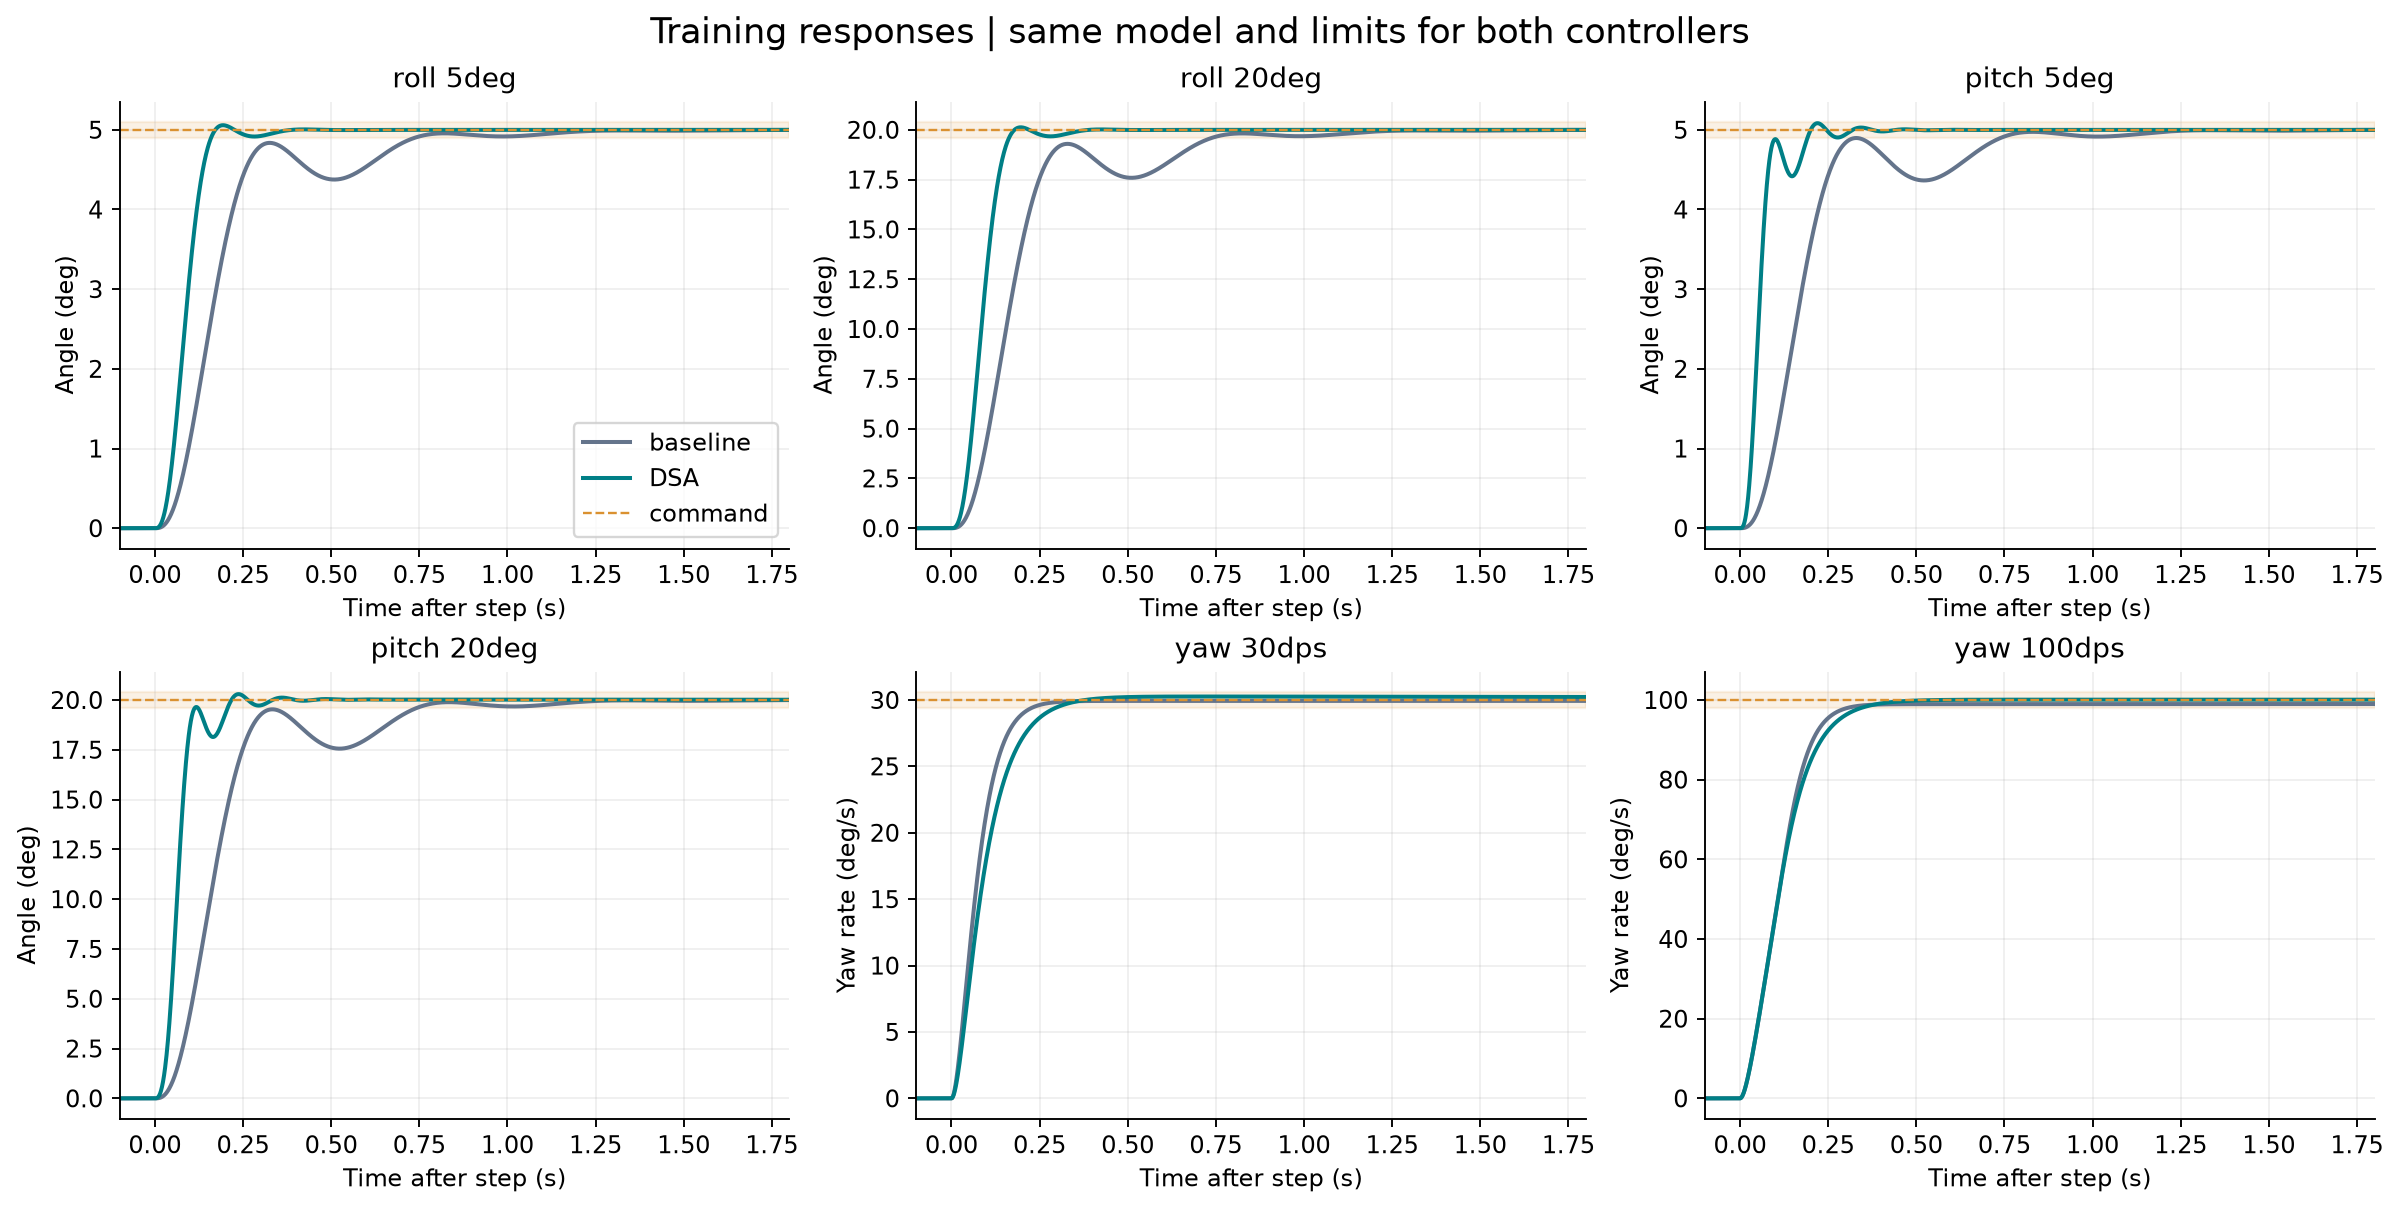

**all work/pid using dolphin swarm/results/plots/02_dsa_iterations.png**

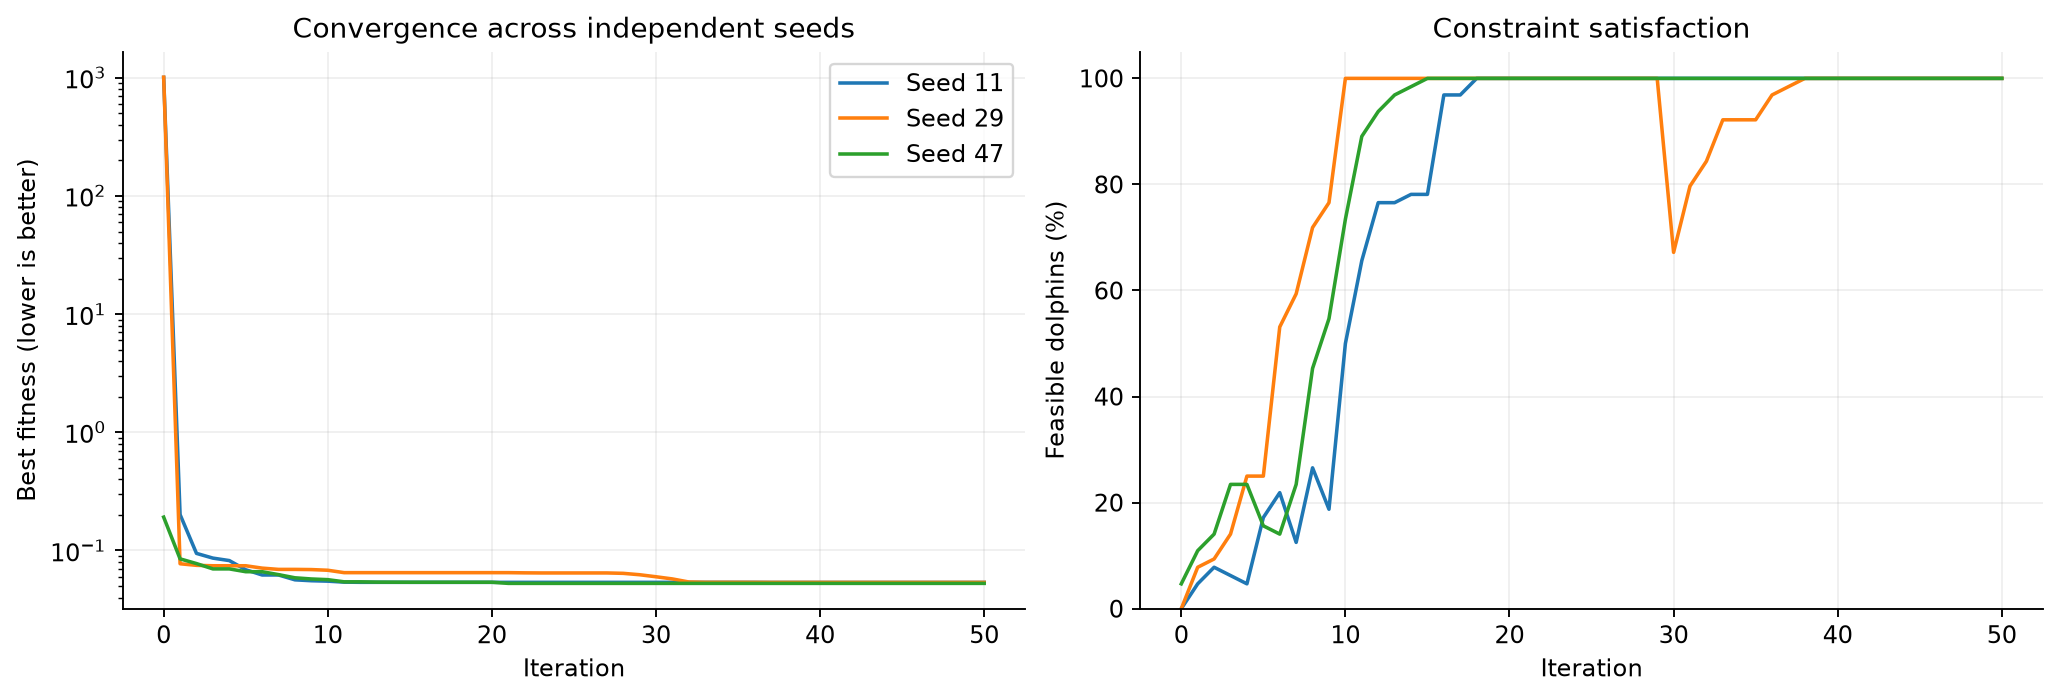

**all work/pid using dolphin swarm/results/plots/03_coupled_and_saturation.png**

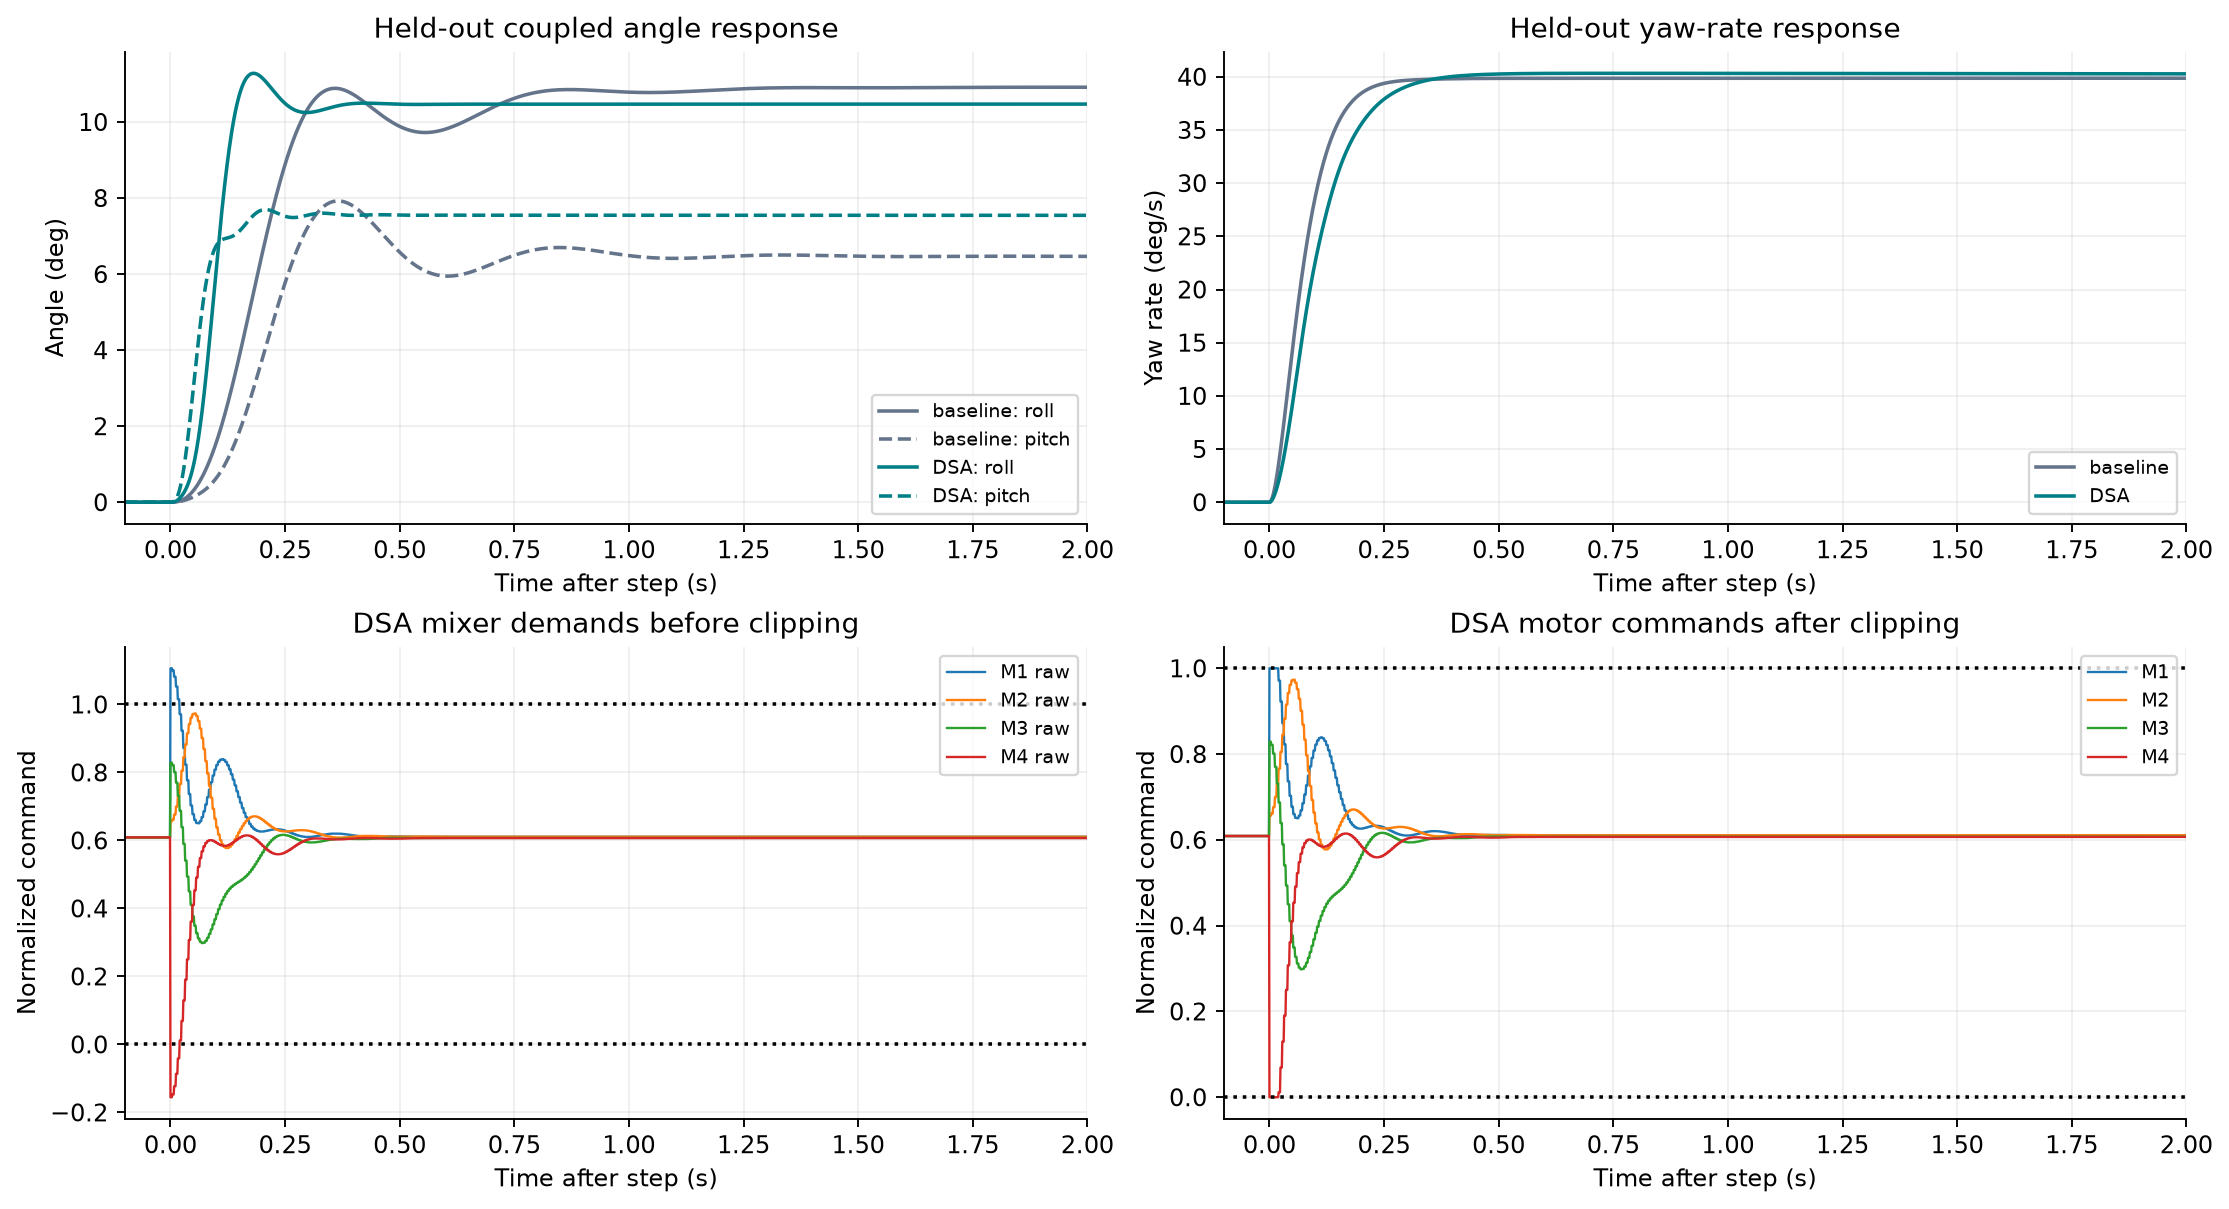

### All saved method figures
- [all work/pid using dolphin swarm/results/plots/01_step_responses.png](../all%20work/pid%20using%20dolphin%20swarm/results/plots/01_step_responses.png)
- [all work/pid using dolphin swarm/results/plots/02_dsa_iterations.png](../all%20work/pid%20using%20dolphin%20swarm/results/plots/02_dsa_iterations.png)
- [all work/pid using dolphin swarm/results/plots/03_coupled_and_saturation.png](../all%20work/pid%20using%20dolphin%20swarm/results/plots/03_coupled_and_saturation.png)
- [all work/pid using dolphin swarm/results/plots/04_inner_loops.png](../all%20work/pid%20using%20dolphin%20swarm/results/plots/04_inner_loops.png)
- [all work/pid using dolphin swarm/results/plots/05_robustness.png](../all%20work/pid%20using%20dolphin%20swarm/results/plots/05_robustness.png)
- [all work/pid using dolphin swarm/results/plots/06_gain_sensitivity.png](../all%20work/pid%20using%20dolphin%20swarm/results/plots/06_gain_sensitivity.png)
- [all work/pid using dolphin swarm/results/plots/07_metric_comparison.png](../all%20work/pid%20using%20dolphin%20swarm/results/plots/07_metric_comparison.png)
- [all work/pid using dolphin swarm/results/plots/08_fitness_components.png](../all%20work/pid%20using%20dolphin%20swarm/results/plots/08_fitness_components.png)
- [all work/pid using dolphin swarm/results/plots/09_robust_candidate.png](../all%20work/pid%20using%20dolphin%20swarm/results/plots/09_robust_candidate.png)
- [all work/pid using dolphin swarm/results/plots/10_method_responses.png](../all%20work/pid%20using%20dolphin%20swarm/results/plots/10_method_responses.png)
- [all work/pid using dolphin swarm/results/plots/11_evaluation_comparison.png](../all%20work/pid%20using%20dolphin%20swarm/results/plots/11_evaluation_comparison.png)

In [8]:
method_figures=figures(METHOD)
show_figures(method_figures,limit=3)
file_links(method_figures,"All saved method figures")


## Try a small fresh optimization (opt-in)
The displayed code uses the original implementation. It runs a small nominal search in `notebook_outputs/`, not the full published experiment. Set the switch to True to execute; new results are not comparable to the full-budget archive.


In [9]:
small_search_code=demo_source(METHOD)
display(Code(small_search_code,language="python"))
RUN_SMALL_SEARCH=False
if RUN_SMALL_SEARCH:
    isolated_python(METHOD,small_search_code,timeout=600)
else:
    print("Small search disabled. Set RUN_SMALL_SEARCH=True to execute.")


from pathlib import Path
import json, os
cfg=json.loads(Path('config.json').read_text())
out=Path(os.environ['PID_NOTEBOOK_OUTPUT'])/'small_search'
out.mkdir(exist_ok=True)
from study import training_scenarios
from dsa import dolphin_swarm
cfg.update(population=8,swarm_size=8,generations=2,iterations=2,workers=1)
result=dolphin_swarm(cfg,training_scenarios(),2026,out)
print('Fresh small-search fitness:',result['fitness'])

Small search disabled. Set RUN_SMALL_SEARCH=True to execute.


## Full experiment and limitations
Use the linked study README for full commands, exact output files, and interpretation. Never run a modified protocol into the archived `results/`. The notebooks do not certify continuous-range robustness, global optimality, Simulink equivalence, or hardware readiness.

[Detailed study guide](../all%20work/pid%20using%20dolphin%20swarm/README.md) · [Data checks](../docs/DATA.md)
